# Check NCBI data

All the sequences data were retrived from NCBI Virus as of 2025-03-10

In [2]:
import pandas as pd
from Bio import SeqIO, Entrez
import matplotlib as mpl
from matplotlib.font_manager import FontProperties
mpl.rcParams['svg.fonttype'] = 'none'
# Path to your Arial.ttf file
arial_font_path = '/Users/skawakubo/python/fonts/Arial.ttf'
# Create a FontProperties object for the Arial font
arial_font = FontProperties(fname=arial_font_path)
mpl.rcParams['font.family'] = arial_font.get_name()
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import time

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [3]:
def fasta_to_dataframe(fasta_file):
    ids = []
    sequences = []
    for record in SeqIO.parse(fasta_file, "fasta"):
        ids.append(record.id)
        sequences.append(str(record.seq))

    df = pd.DataFrame({
        "ID": ids,
        "seq": sequences
    })
    return df

In [4]:
# Read the fasta file
FCoV_NCBI_seq_path = "/Users/skawakubo/Library/CloudStorage/Dropbox/TheSatoLab/Izumi_FIP/sequence_data/NCBI_Virus_250310/sequences.fasta"
FCoV_NCBI_seq = fasta_to_dataframe(FCoV_NCBI_seq_path)
FCoV_NCBI_seq.rename(columns={"ID": "Accession"}, inplace=True)
FCoV_NCBI_seq

,Accession,seq
0,NC_002306.3,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTA...
1,PV135972.1,TTTCTTAACACTCTAAGTTTTATAGTCACTAACCAACATGTGATTG...
2,PQ641430.1,GCTATAACAGCCATTAATCAAACTGATCTGTTTGAATTTGTAAATC...
3,PQ641431.1,GCTATAACAGCCGTTAATCAGACTGATTTGTTTGAGTTTGTAACTC...
4,PQ641432.1,GCTATAACTTCTGTTAATCAAACTGATCTGTTTGAGTTTGTAAATC...
...,...,...
4069,A22378.1,TAAATTATATGTTTGTGAATGACCTCACGTTGCATTTTGTAGACCC...
4070,M23694.1,TGGAGGCATACACAGATGTGTTTGATGACACACAGGTTGAGATGAT...
4071,X66718.1,GATGACACACAGGTTGAGATGATCGATGAGGTAACGAACTAAACGC...
4072,X56496.1,AAACCAAGGCATATAATCCCGACGAAGCATTTTTGGTTTGAACTAA...


In [5]:
# Read the metadata
FCoV_NCBI_meta_path = "/Users/skawakubo/Library/CloudStorage/Dropbox/TheSatoLab/Izumi_FIP/sequence_data/NCBI_Virus_250310/sequences.tsv"
FCoV_NCBI_meta = pd.read_csv(FCoV_NCBI_meta_path, sep="\t")
FCoV_NCBI_meta

,Accession,Organism_Name,GenBank_RefSeq,Assembly,SRA_Accession,Submitters,Organization,Org_location,Release_Date,Isolate,...,Nuc_Completeness,Genotype,Publications,Geo_Location,Country,USA,Host,Tissue_Specimen_Source,Collection_Date,GenBank_Title
0,NC_002306.3,Feline infectious peritonitis virus,RefSeq,GCF_000856025.1,NaN,"Haijema,B.J., de Groot-Mijnes,J.D.F., Vennema,...","National Center for Biotechnology Information,...",USA,2000-05-11,79-1146,...,complete,2,NaN,USA,USA,NaN,NaN,NaN,NaN,"Feline infectious peritonitis virus, complete ..."
1,PV135972.1,Feline coronavirus,GenBank,NaN,NaN,"Cretu,D.M., Baraitareanu,S., Gurau,R.M.","USAMV Bucharest, Infectious Disease",Romania,2025-02-26,RO-FCOVS4-2025,...,partial,NaN,NaN,Romania,Romania,NaN,Felis catus,feces,2023-03-14,Feline coronavirus isolate RO-FCOVS4-2025 ORF3...
2,PQ641430.1,Feline coronavirus,GenBank,NaN,NaN,"Pongsiwat,S., Bhusri,B., Tangsudjai,S., Saechi...","Faculty of Veterinary Science, Mahidol Univers...",Thailand,2025-01-28,MW12/66,...,partial,NaN,NaN,Thailand,Thailand,NaN,Felis catus,feces,2023,Feline coronavirus isolate MW12/66 spike prote...
3,PQ641431.1,Feline coronavirus,GenBank,NaN,NaN,"Pongsiwat,S., Bhusri,B., Tangsudjai,S., Saechi...","Faculty of Veterinary Science, Mahidol Univers...",Thailand,2025-01-28,MW16/66,...,partial,NaN,NaN,Thailand,Thailand,NaN,Felis catus,feces,2023,Feline coronavirus isolate MW16/66 spike prote...
4,PQ641432.1,Feline coronavirus,GenBank,NaN,NaN,"Pongsiwat,S., Bhusri,B., Tangsudjai,S., Saechi...","Faculty of Veterinary Science, Mahidol Univers...",Thailand,2025-01-28,MW1206/66,...,partial,NaN,NaN,Thailand,Thailand,NaN,Felis catus,NaN,2023,Feline coronavirus isolate MW1206/66 spike pro...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4069,A22378.1,Feline infectious peritonitis virus,GenBank,set:A22378,NaN,"Vennema,H., Rottier,P.J.",NaN,NaN,1994-10-20,NaN,...,partial,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Feline Infectious Virus (FIPV) genes M and N
4070,M23694.1,Feline infectious peritonitis virus,GenBank,set:M23694,NaN,"De Groot,R.J., Andeweg,A.C., Horzinek,M.C., Sp...",NaN,NaN,1993-08-02,NaN,...,partial,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,Feline infectious peritonitis virus ORF1 and O...
4071,X66718.1,Feline coronavirus,GenBank,set:X66718,NaN,"Vennema,H., Rossen,J.W., Wesseling,J., Horzine...","H. Vennema, University of Utrecht, Dept. of Vi...",Netherlands,1993-05-11,FECV WSU 79-1683,...,partial,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,Feline coronavirus mRNA for ORF6a and ORF6b
4072,X56496.1,Feline infectious peritonitis virus,GenBank,set:X56496,NaN,"Vennema,H., de Groot,R.J., Harbour,D.A., Horzi...","Vennema H., Department of Virology, Institute ...",Netherlands,1991-03-25,WSU 79-1146,...,partial,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,Feline infectious peritonitis virus (FIPV) gen...


In [6]:
# Merge the metadata and the sequence
FCoV_NCBI = pd.merge(FCoV_NCBI_meta, FCoV_NCBI_seq, on="Accession")
FCoV_NCBI

,Accession,Organism_Name,GenBank_RefSeq,Assembly,SRA_Accession,Submitters,Organization,Org_location,Release_Date,Isolate,...,Genotype,Publications,Geo_Location,Country,USA,Host,Tissue_Specimen_Source,Collection_Date,GenBank_Title,seq
0,NC_002306.3,Feline infectious peritonitis virus,RefSeq,GCF_000856025.1,NaN,"Haijema,B.J., de Groot-Mijnes,J.D.F., Vennema,...","National Center for Biotechnology Information,...",USA,2000-05-11,79-1146,...,2,NaN,USA,USA,NaN,NaN,NaN,NaN,"Feline infectious peritonitis virus, complete ...",ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTA...
1,PV135972.1,Feline coronavirus,GenBank,NaN,NaN,"Cretu,D.M., Baraitareanu,S., Gurau,R.M.","USAMV Bucharest, Infectious Disease",Romania,2025-02-26,RO-FCOVS4-2025,...,NaN,NaN,Romania,Romania,NaN,Felis catus,feces,2023-03-14,Feline coronavirus isolate RO-FCOVS4-2025 ORF3...,TTTCTTAACACTCTAAGTTTTATAGTCACTAACCAACATGTGATTG...
2,PQ641430.1,Feline coronavirus,GenBank,NaN,NaN,"Pongsiwat,S., Bhusri,B., Tangsudjai,S., Saechi...","Faculty of Veterinary Science, Mahidol Univers...",Thailand,2025-01-28,MW12/66,...,NaN,NaN,Thailand,Thailand,NaN,Felis catus,feces,2023,Feline coronavirus isolate MW12/66 spike prote...,GCTATAACAGCCATTAATCAAACTGATCTGTTTGAATTTGTAAATC...
3,PQ641431.1,Feline coronavirus,GenBank,NaN,NaN,"Pongsiwat,S., Bhusri,B., Tangsudjai,S., Saechi...","Faculty of Veterinary Science, Mahidol Univers...",Thailand,2025-01-28,MW16/66,...,NaN,NaN,Thailand,Thailand,NaN,Felis catus,feces,2023,Feline coronavirus isolate MW16/66 spike prote...,GCTATAACAGCCGTTAATCAGACTGATTTGTTTGAGTTTGTAACTC...
4,PQ641432.1,Feline coronavirus,GenBank,NaN,NaN,"Pongsiwat,S., Bhusri,B., Tangsudjai,S., Saechi...","Faculty of Veterinary Science, Mahidol Univers...",Thailand,2025-01-28,MW1206/66,...,NaN,NaN,Thailand,Thailand,NaN,Felis catus,NaN,2023,Feline coronavirus isolate MW1206/66 spike pro...,GCTATAACTTCTGTTAATCAAACTGATCTGTTTGAGTTTGTAAATC...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4069,A22378.1,Feline infectious peritonitis virus,GenBank,set:A22378,NaN,"Vennema,H., Rottier,P.J.",NaN,NaN,1994-10-20,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Feline Infectious Virus (FIPV) genes M and N,TAAATTATATGTTTGTGAATGACCTCACGTTGCATTTTGTAGACCC...
4070,M23694.1,Feline infectious peritonitis virus,GenBank,set:M23694,NaN,"De Groot,R.J., Andeweg,A.C., Horzinek,M.C., Sp...",NaN,NaN,1993-08-02,NaN,...,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,Feline infectious peritonitis virus ORF1 and O...,TGGAGGCATACACAGATGTGTTTGATGACACACAGGTTGAGATGAT...
4071,X66718.1,Feline coronavirus,GenBank,set:X66718,NaN,"Vennema,H., Rossen,J.W., Wesseling,J., Horzine...","H. Vennema, University of Utrecht, Dept. of Vi...",Netherlands,1993-05-11,FECV WSU 79-1683,...,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,Feline coronavirus mRNA for ORF6a and ORF6b,GATGACACACAGGTTGAGATGATCGATGAGGTAACGAACTAAACGC...
4072,X56496.1,Feline infectious peritonitis virus,GenBank,set:X56496,NaN,"Vennema,H., de Groot,R.J., Harbour,D.A., Horzi...","Vennema H., Department of Virology, Institute ...",Netherlands,1991-03-25,WSU 79-1146,...,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,Feline infectious peritonitis virus (FIPV) gen...,AAACCAAGGCATATAATCCCGACGAAGCATTTTTGGTTTGAACTAA...


In [7]:
print(FCoV_NCBI["Organism_Name"].value_counts())

Organism_Name
Feline coronavirus                     3888
Feline infectious peritonitis virus     151
Acinonyx jubatus coronavirus              9
Feline coronavirus UU54                   1
Feline coronavirus UU40                   1
Feline coronavirus UU9                    1
Feline coronavirus UU3                    1
Feline coronavirus UU2                    1
Feline coronavirus UU10                   1
Feline coronavirus UU16                   1
Feline coronavirus UU15                   1
Feline coronavirus UU5                    1
Feline coronavirus UU8                    1
Feline coronavirus UU4                    1
Feline coronavirus UU7                    1
Feline coronavirus UU11                   1
Feline coronavirus RM                     1
Feline coronavirus UU23                   1
Feline coronavirus UU47                   1
Feline coronavirus UU34                   1
Feline coronavirus UU31                   1
Feline coronavirus UU24                   1
Feline coronavirus

In [8]:
print(FCoV_NCBI["Tissue_Specimen_Source"].value_counts())

Tissue_Specimen_Source
feces                       999
abdominal cavity            665
feces, abdominal cavity     108
blood                        83
lung                         71
lymph                        43
liver, abdominal cavity      40
kidney, abdominal cavity     27
brain                        12
spleen, abdominal cavity     10
eye                           2
spinal cord                   1
cerebrospinal fluid           1
tonsil                        1
heart                         1
Name: count, dtype: int64


In [9]:
print(FCoV_NCBI['Genotype'].value_counts())
# number of nan values in the Genotype column
#FCoV_NCBI['Genotype'].isnull().sum()

Genotype
1          298
I          246
type I      61
type 1      50
II          19
2            5
type II      2
Name: count, dtype: int64


In [10]:
# select only the important columns
FCoV_NCBI_selected = FCoV_NCBI[["Accession", "Isolate", "Collection_Date", "Country", "Host", "Tissue_Specimen_Source", "Length", "seq"]]
FCoV_NCBI_selected

,Accession,Isolate,Collection_Date,Country,Host,Tissue_Specimen_Source,Length,seq
0,NC_002306.3,79-1146,NaN,USA,NaN,NaN,29355,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTA...
1,PV135972.1,RO-FCOVS4-2025,2023-03-14,Romania,Felis catus,feces,687,TTTCTTAACACTCTAAGTTTTATAGTCACTAACCAACATGTGATTG...
2,PQ641430.1,MW12/66,2023,Thailand,Felis catus,feces,103,GCTATAACAGCCATTAATCAAACTGATCTGTTTGAATTTGTAAATC...
3,PQ641431.1,MW16/66,2023,Thailand,Felis catus,feces,103,GCTATAACAGCCGTTAATCAGACTGATTTGTTTGAGTTTGTAACTC...
4,PQ641432.1,MW1206/66,2023,Thailand,Felis catus,NaN,103,GCTATAACTTCTGTTAATCAAACTGATCTGTTTGAGTTTGTAAATC...
...,...,...,...,...,...,...,...,...
4069,A22378.1,NaN,NaN,NaN,NaN,NaN,2517,TAAATTATATGTTTGTGAATGACCTCACGTTGCATTTTGTAGACCC...
4070,M23694.1,NaN,NaN,NaN,NaN,NaN,1272,TGGAGGCATACACAGATGTGTTTGATGACACACAGGTTGAGATGAT...
4071,X66718.1,FECV WSU 79-1683,NaN,NaN,NaN,NaN,957,GATGACACACAGGTTGAGATGATCGATGAGGTAACGAACTAAACGC...
4072,X56496.1,WSU 79-1146,NaN,NaN,NaN,NaN,2000,AAACCAAGGCATATAATCCCGACGAAGCATTTTTGGTTTGAACTAA...


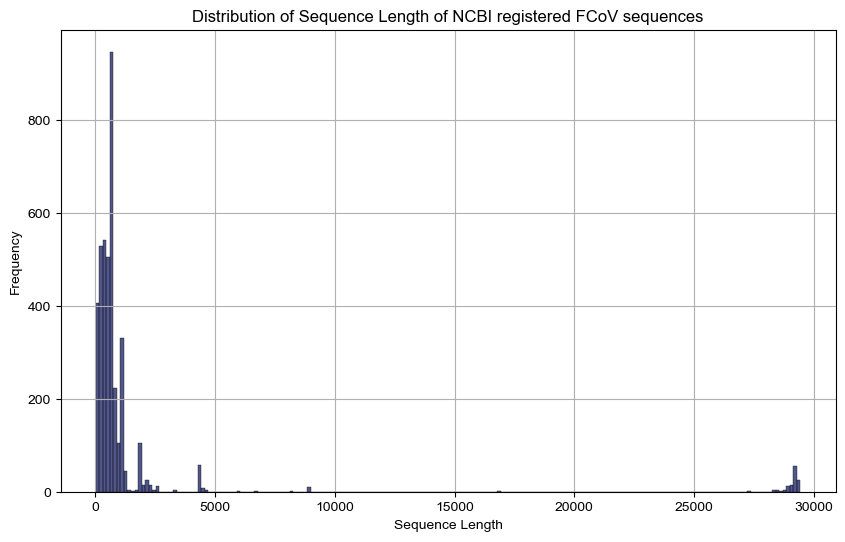

In [11]:
# plot the distribution of the sequence length
plt.figure(figsize=(10, 6))
sns.histplot(FCoV_NCBI_selected['Length'], bins=200, alpha=0.7, color='#091057')
plt.title("Distribution of Sequence Length of NCBI registered FCoV sequences")
plt.xlabel("Sequence Length")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

In [12]:
# select only the sequences with the length longer than 25000
FCoV_NCBI_selected_almostfull = FCoV_NCBI_selected[FCoV_NCBI_selected['Length'] > 25000]
FCoV_NCBI_selected_almostfull

,Accession,Isolate,Collection_Date,Country,Host,Tissue_Specimen_Source,Length,seq
0,NC_002306.3,79-1146,NaN,USA,NaN,NaN,29355,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTA...
17,PP254206.1,ZD/22/332i,2022-07-17,India,Felis catus,feces,29229,TCTGCTTTTGCTTTAACCTGCCTTGTGCTAGATTTGTCTTCGGACA...
18,PP254207.1,ZD/22/337i,2022-07-17,India,Felis catus,feces,29229,AACTCTGCTTGGGGTTTAACCTGCCTTGTGCTAGATTTGTCTTCGG...
19,PP254208.1,ZD/22/385i,2022-07-19,India,Felis catus,feces,29286,TCTTCATTTAKTTTAACCTGCCTTGTGCTAGATTTGTCTTCGGACA...
20,PP254209.1,ZD/22/519i,2022-07-21,India,Felis catus,feces,29221,TCTTCGTTTGCTTTAACCTGCCTTGTGCTAGATTTGTCTTCGGACA...
...,...,...,...,...,...,...,...,...
3824,EU186072.1,Black,NaN,USA,NaN,NaN,29256,ACTTTTAAAGTAAAGTGAGTGTAGCTGGGCTATAACTCTTCATTTA...
3888,DQ286389.1,NaN,NaN,USA,NaN,NaN,28632,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTA...
3889,DQ848678.1,NaN,NaN,NaN,NaN,abdominal cavity,29277,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTC...
3939,DQ010921.1,VR-2202 (P100),NaN,NaN,Felis catus,NaN,29147,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTTTTTTT...


# Check original data from Izumi

In [13]:
FCoV_Izumi_seq_path = "/Users/skawakubo/Library/CloudStorage/Dropbox/TheSatoLab/Izumi_FIP/sequence_data/FCoV_seq_Izumi_v2_250310_renamed_mafft.fasta"
FCoV_Izumi_seq = fasta_to_dataframe(FCoV_Izumi_seq_path)
FCoV_Izumi_seq['seq'] = FCoV_Izumi_seq['seq'].str.upper()
FCoV_Izumi_seq

,ID,seq
0,v11-1_S79,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
1,v8-1_S91,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
2,V7-11_S129,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
3,V6-11_S105,----------------------------------------------...
4,V5-S_S8,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
5,V004,-ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTA...
6,V3-S_S7,------------NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
7,V2-10_S68,----------------------------------------------...
8,V1-10_S56,----------------------------------------------...
9,RGU3-1_S43,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...


In [20]:
# merge only the genome data of NCBI and Izumi
FCoV_NCBI_selected_almostfull_for_merge = FCoV_NCBI_selected_almostfull[["Accession", "seq"]]
FCoV_NCBI_selected_almostfull_for_merge.rename(columns={"Accession": "ID"}, inplace=True)

/var/folders/9v/b3wtpj5n6f30_z6c2cnt7rdr0000gn/T/ipykernel_32419/417479005.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  FCoV_NCBI_selected_almostfull_for_merge.rename(columns={"Accession": "ID"}, inplace=True)


In [24]:
# remove '-' from the sequence
FCoV_Izumi_seq_for_merge = FCoV_Izumi_seq.copy()
FCoV_Izumi_seq_for_merge['seq'] = FCoV_Izumi_seq_for_merge['seq'].str.replace("-", "")
FCoV_Izumi_seq_for_merge

,ID,seq
0,v11-1_S79,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
1,v8-1_S91,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
2,V7-11_S129,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
3,V6-11_S105,NNNNNNNNNNNNNNNCGGACACCAACTCGAACTAAACGAAATATTT...
4,V5-S_S8,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
5,V004,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTAT...
6,V3-S_S7,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
7,V2-10_S68,NNNTGGACTGGGTTTAAGACTTCTTGTTGTGGTCTTCATGGCAAAG...
8,V1-10_S56,GACTGGACTGGTTTTAAGACTGCTTGCTGTGGTCTTCATGGCAAAG...
9,RGU3-1_S43,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...


In [25]:
# merge the NCBI and Izumi data
FCoV_all = pd.concat([FCoV_NCBI_selected_almostfull_for_merge, FCoV_Izumi_seq_for_merge], ignore_index=True)
FCoV_all

,ID,seq
0,NC_002306.3,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTA...
1,PP254206.1,TCTGCTTTTGCTTTAACCTGCCTTGTGCTAGATTTGTCTTCGGACA...
2,PP254207.1,AACTCTGCTTGGGGTTTAACCTGCCTTGTGCTAGATTTGTCTTCGG...
3,PP254208.1,TCTTCATTTAKTTTAACCTGCCTTGTGCTAGATTTGTCTTCGGACA...
4,PP254209.1,TCTTCGTTTGCTTTAACCTGCCTTGTGCTAGATTTGTCTTCGGACA...
...,...,...
145,H2-10_S116,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
146,775024S_S3_L001,GGACACCAACTCGAACTAAACGAAATATTTGTCTCTCTATGAAACC...
147,IZ_1_S7_L001,TTTACTTTGAGTGGCTTAGTGCTACGTTTGTCTTCGGACACCAACT...
148,771819S_S4_L001,CGGACACCAACTCGAACTAAACGAAATATTTGTCTCTCTATGAAAC...


In [26]:
# write the merged data to a fasta file
# Define the output FASTA file path
output_file = '/Users/skawakubo/Library/CloudStorage/Dropbox/TheSatoLab/Izumi_FIP/sequence_data/FCoV_full_NCBI_Izumi.fasta'

# Open the file in write mode
with open(output_file, 'w') as fasta_file:
    # Iterate over each row in the DataFrame
    for index, row in FCoV_all.iterrows():
        # Write the header line with '>'
        fasta_file.write(f'>{row["ID"]}\n')
        # Write the sequence line
        fasta_file.write(f'{row["seq"]}\n')

In [27]:
# run the mafft
!mafft --auto /Users/skawakubo/Library/CloudStorage/Dropbox/TheSatoLab/Izumi_FIP/sequence_data/FCoV_full_NCBI_Izumi.fasta > /Users/skawakubo/Library/CloudStorage/Dropbox/TheSatoLab/Izumi_FIP/sequence_data/FCoV_full_NCBI_Izumi_mafft.fasta

nthread = 0
nthreadpair = 0
nthreadtb = 0
ppenalty_ex = 0
stacksize: 8176 kb
generating a scoring matrix for nucleotide (dist=200) ... done
Gap Penalty = -1.53, +0.00, +0.00



Making a distance matrix ..

There are 218114 ambiguous characters.
  101 / 150
done.

Constructing a UPGMA tree (efffree=0) ... 
  140 / 150
done.

Progressive alignment 1/2... 
STEP    68 / 149 
Reallocating..done. *alloclen = 60532
STEP    69 / 149 
len1=30249, len2=29283, Switching to the memsave mode
STEP    75 / 149 mP 00002 / 00080DP 00003 / 00080DP 00004 / 00080DP 00005 / 00080DP 00006 / 00080DP 00007 / 00080DP 00008 / 00080DP 00009 / 00080DP 00010 / 00080DP 00011 / 00080DP 00012 / 00080DP 00013 / 00080DP 00014 / 00080DP 00015 / 00080DP 00016 / 00080DP 00017 / 00080DP 00018 / 00080DP 00019 / 00080DP 00020 / 00080DP 00021 / 00080DP 00022 / 00080DP 00023 / 00080DP 00024 / 00080DP 00025 / 00080DP 00026 / 00080DP 00027 / 00080DP 00028 / 00080DP 00029 / 00080DP 00030 / 00080DP 00031 / 00080DP 00032 / 00080DP 

# retrive metadata from NCBI entry

If biotype information (explicitly stated if FIPV or FECV) of each sequence can be added by redownloading the NCBI database, the code bellow is useful. Still in progress...

In [15]:
# Retrieve the sequence of the reference genome from NCBI
Entrez.email = "skawakubo@g.ecc.u-tokyo.ac.jp" 


def fetch_genbank_data(accession_id):
    with Entrez.efetch(db="nuccore", id=accession_id, rettype="gb", retmode="text") as handle:
        record = SeqIO.read(handle, "genbank")
    return record

# Accession numbers of genomes to be retrieved
accession_list = ["NC_002306.3", "PP254206.1", "PP254207.1"] 

records = []

for acc in accession_list:
    record = fetch_genbank_data(acc)
    if record:
        records.append(record)
        time.sleep(1)


# handle = Entrez.efetch(db='nuccore', id='NC_002306.3', rettype='gb', retmode='text')
# record = SeqIO.read(handle, "genbank")
# handle.close()
# print(record)

In [16]:
for record in records:
    print(record.id, record.features[0].qualifiers['serotype'][0])

NC_002306.3 2
PP254206.1 1
PP254207.1 1


In [17]:
record.features[0].qualifiers

OrderedDict([('organism', ['Feline coronavirus']),
             ('mol_type', ['genomic RNA']),
             ('serotype', ['1']),
             ('isolate', ['ZD/22/337i']),
             ('isolation_source', ['rectal swab']),
             ('host', ['Felis catus']),
             ('db_xref', ['taxon:12663']),
             ('geo_loc_name', ['India: Nashik']),
             ('collection_date', ['17-Jul-2022'])])

In [18]:
for record in records:
    print(record.features[0].qualifiers)

OrderedDict([('organism', ['Feline infectious peritonitis virus']), ('mol_type', ['genomic RNA']), ('serotype', ['2']), ('isolate', ['79-1146']), ('db_xref', ['taxon:11135']), ('geo_loc_name', ['USA'])])
OrderedDict([('organism', ['Feline coronavirus']), ('mol_type', ['genomic RNA']), ('serotype', ['1']), ('isolate', ['ZD/22/332i']), ('isolation_source', ['rectal swab']), ('host', ['Felis catus']), ('db_xref', ['taxon:12663']), ('geo_loc_name', ['India: Nashik']), ('collection_date', ['17-Jul-2022'])])
OrderedDict([('organism', ['Feline coronavirus']), ('mol_type', ['genomic RNA']), ('serotype', ['1']), ('isolate', ['ZD/22/337i']), ('isolation_source', ['rectal swab']), ('host', ['Felis catus']), ('db_xref', ['taxon:12663']), ('geo_loc_name', ['India: Nashik']), ('collection_date', ['17-Jul-2022'])])


In [19]:
# print the metadata of all records
for record in records:
    for key, value in record.annotations.items():
        print(f"{key}: {value}")
    print("\n")

molecule_type: RNA
topology: linear
data_file_division: VRL
date: 13-AUG-2018
accessions: ['NC_002306', 'NC_007025', 'NC_012937', 'NC_012938', 'NC_012939', 'NC_012940', 'NC_012941', 'NC_012942', 'NC_012951', 'NC_012952', 'NC_012953', 'NC_012954', 'NC_012955', 'NC_012956', 'NC_013794', 'NC_013795']
sequence_version: 3
keywords: ['RefSeq']
source: Feline infectious peritonitis virus
organism: Feline infectious peritonitis virus
taxonomy: ['Viruses', 'Riboviria', 'Orthornavirae', 'Pisuviricota', 'Pisoniviricetes', 'Nidovirales', 'Cornidovirineae', 'Coronaviridae', 'Orthocoronavirinae', 'Alphacoronavirus', 'Tegacovirus', 'Alphacoronavirus 1']
references: [Reference(title='Direct Submission', ...), Reference(title='Direct Submission', ...)]
comment: PROVISIONAL REFSEQ: This record has not yet been subject to final
NCBI review. The reference sequence is identical to AY994055.
On or before Dec 17, 2010 this sequence version replaced
NC_012952.1, NC_012938.1, NC_012956.1, NC_012955.1, NC_01295